# 04 – Tren en lineær klassifikator

**Mål:** trene en lineær modell på Fashion-MNIST med standard PyTorch treningsløkke og evaluere på usette bilder.
Vi bygger videre på modellen fra forrige notatbok.

Den lineære modellen tilsvarer **logistisk regresjon**
for flere klasser. Hver piksel er en *feature*. Modellen lærer én vekt per piksel og ett konstantledd per klasse.


In [8]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn


In [9]:
from pytorch_101.utils import download_fashion_mnist, seed_everything

train_data, test_data = download_fashion_mnist()
print(f"Treningsbilder: {len(train_data)}, testbilder: {len(test_data)}")


Treningsbilder: 20000, testbilder: 1000


## Grupper til trening og evaluering

Hjelpefunksjonen velger 20 000 treningsbilder og 1 000 testbilder fra Fashion-MNIST.
Som i forrige notebook oppretter vi datalasterne direkte.


In [10]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_data, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(42))
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)


## Tap og optimizer

`nn.CrossEntropyLoss()` sammenligner modellens rå skårer `[B, 10]` med riktige
klasseindekser `[B]` av typen `int64`. Den gir ett tapstall, der lavere er bedre.

En **optimizer** oppdaterer modellens parametere. Vi bruker Adam med læringsrate
0.001. Læringsraten styrer størrelsen på oppdateringene.


## Oppgave 1: Sett opp Fashion-MNIST-modellen

Start med `seed_everything(42)` for å få reproduserbare startvekter.
Lag `model` med `nn.Flatten()` og `nn.Linear(784, 10)`, som i notebook 03.
Lag `loss_fn = nn.CrossEntropyLoss()` og `optimizer` med
`torch.optim.Adam`, modellens parametere og læringsrate 0.001.

<details>
<summary>Hint</summary>

Optimizer må få `model.parameters()` fra akkurat den modellen du trener.

</details>


In [11]:
seed_everything(42)
model = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
print(model)


Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=10, bias=True)
)


**Kontroll:** Kjør denne cellen når du har løst oppgaven. En feilmelding betyr at du må undersøke løsningen.


In [12]:
assert model(torch.zeros(2, 1, 28, 28)).shape == (2, 10)


## Eksempel: én oppdatering på Fashion-MNIST

Har dere brukt `model.fit(X, y)` i scikit-learn, har biblioteket gjort
arbeidet med å tilpasse modellens parametere. Her skriver vi treningsløkken
selv. Vektene og konstantleddene i `model.parameters()` er koeffisientene
vi skal tilpasse. Ulike modeller og biblioteker kan bruke ulike metoder til dette;
her bruker vi Adam.

**For hver batch utføres følgende steg:**

1. Nullstill gamle gradienter: `optimizer.zero_grad()`.
2. Beregn skårer fra bildene: `scores = model(images)`.
3. Beregn tapet mot riktige klasser: `loss = loss_fn(scores, labels)`.
4. Beregn gradientene: `loss.backward()`.
5. Oppdater parametrene: `optimizer.step()`.

Prosedyren gjentas for hver batch gjennom alle epokene.

`backward()` beregner gradienten til tapet med hensyn på modellparametrene ved hjelp av automatisk derivasjon.
`step()` bruker gradientene til å oppdatere parametrene i henhold til Adam.

PyTorch summerer gradienter ved hvert kall til `backward()`. Vi nullstiller
dem før neste batch slik at oppdateringen bruker gradientene fra denne batchen.

Vi beregner tapet på **samme batch** før og etter oppdateringen for å undersøke
virkningen.


In [13]:
images, labels = next(iter(train_loader))
model.train()
optimizer.zero_grad()  # 1. Nullstill gamle gradienter
scores = model(images)  # 2. Beregn skårer
loss = loss_fn(scores, labels)  # 3. Beregn tap
loss.backward()  # 4. Beregn gradienter
optimizer.step()  # 5. Oppdater parametere
print("Tap før oppdateringen:", loss.item())

# Mål tapet på de samme bildene med de oppdaterte parametrene.
with torch.no_grad():
    loss_after = loss_fn(model(images), labels)
print("Tap etter oppdateringen:", loss_after.item())


Tap før oppdateringen: 2.3298566341400146
Tap etter oppdateringen: 2.1947102546691895


## Fra én batch til flere epoker

Sammenlign tapet før og etter oppdateringen. Hva endret seg i modellen?
Er målingen på denne batchen nok til å si om modellen fungerer på usette bilder?

En **epoke** er én gjennomgang av treningsutvalget. Hver batch gir én oppdatering.


## Oppgave 2: Skriv treningsløkken

Start med en ny modell og en ny Adam-optimizer som i oppgave 1, slik at
oppdateringen i eksemplet over ikke blir med i treningen. Bruk frø 42 igjen
og opprett `train_loader` på nytt med samme innstillinger og lastergenerator.
Tren modellen i 25 epoker. Lag `training_loss = []`.
For hver epoke:

1. Kall `model.train()` og sett `loss_sum = 0.0`.
2. Gå gjennom `train_loader` og bruk de fem stegene fra eksemplet over.
3. Legg `loss.item() * len(images)` til tapsummen for hver batch.
4. Del summen på `len(train_data)`, lagre i `training_loss` og skriv ut tapet.

Vis deretter `training_loss` som en kurve med epoke på x-aksen og
gjennomsnittlig treningstap på y-aksen.

Bruk læringsrate 0.001 og batchstørrelse 64, som i notatbok 05.


Epoke 1: treningstap 0.8433
Epoke 2: treningstap 0.5733
Epoke 3: treningstap 0.5155
Epoke 4: treningstap 0.4878
Epoke 5: treningstap 0.4680
Epoke 6: treningstap 0.4530
Epoke 7: treningstap 0.4408
Epoke 8: treningstap 0.4329
Epoke 9: treningstap 0.4255
Epoke 10: treningstap 0.4202
Epoke 11: treningstap 0.4149
Epoke 12: treningstap 0.4091
Epoke 13: treningstap 0.4030
Epoke 14: treningstap 0.4003
Epoke 15: treningstap 0.3949
Epoke 16: treningstap 0.3935
Epoke 17: treningstap 0.3908
Epoke 18: treningstap 0.3862
Epoke 19: treningstap 0.3843
Epoke 20: treningstap 0.3833
Epoke 21: treningstap 0.3787
Epoke 22: treningstap 0.3769
Epoke 23: treningstap 0.3773
Epoke 24: treningstap 0.3713
Epoke 25: treningstap 0.3697


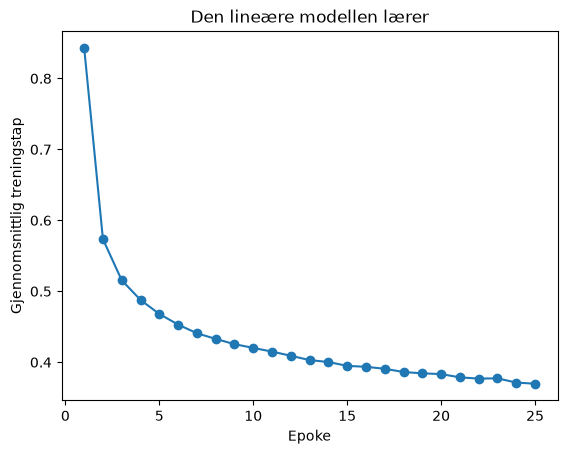

In [14]:
seed_everything(42)
model = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(42))

training_loss = []
for epoch in range(25):
    model.train()
    loss_sum = 0.0
    for images, labels in train_loader:
        optimizer.zero_grad()
        scores = model(images)
        loss = loss_fn(scores, labels)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(images)
    mean_loss = loss_sum / len(train_data)
    training_loss.append(mean_loss)
    print(f"Epoke {epoch + 1}: treningstap {mean_loss:.4f}")

fig, ax = plt.subplots()
ax.plot(range(1, 26), training_loss, marker="o")
ax.set(xlabel="Epoke", ylabel="Gjennomsnittlig treningstap", title="Den lineære modellen lærer")
plt.show()


**Kontroll:** Kjør denne cellen når du har løst oppgaven. En feilmelding betyr at du må undersøke løsningen.


In [15]:
assert len(training_loss) == 25
assert all(np.isfinite(training_loss))
assert training_loss[-1] < training_loss[0]


### Refleksjon

Oppgi første og siste treningstap. Hva antyder utviklingen?
Hva er forskjellen på én batch og én epoke?
Hva gjør `backward()` og `step()` hver for seg?


**Mitt svar:**

Koden over viser første og siste treningstap fra kjøringen. Bruk disse tallene.
Lavere tap viser bedre tilpasning til treningsdata etter tapsfunksjonens mål,
men beviser ikke at modellen fungerer godt på nye bilder.
En batch er én gruppe bilder og gir én oppdatering; en epoke går gjennom alle
treningsbildene. `backward()` beregner gradienter, mens `step()` oppdaterer parametrene.


## Evaluering

`model.eval()` velger evalueringsmodus. For modellen vår med bare `Flatten`
og `Linear` endrer dette ikke beregningene. Vi bruker likevel standardmønsteret:
andre lagtyper kan oppføre seg forskjellig under trening og evaluering.
`eval()` fryser ikke parametrene og slår ikke av gradientberegning.

`torch.no_grad()` slår av beregninger for gradienter.
Vi bruker begge og oppdaterer ingen parametere på testdata.


## Oppgave 3: Evaluer på testbilder

Sett modellen i evalueringsmodus. Under `torch.no_grad()`: gå gjennom
`test_loader`, beregn skårer, velg prediksjoner og tell riktige.
Lag `test_accuracy` som antall riktige delt på antall testbilder.
Skriv ut resultatet som prosent.

<details>
<summary>Hint</summary>

Start med `num_correct = 0`. Bruk `(predictions == labels).sum().item()`.

</details>

Rapporter også `num_correct` av `len(test_data)`; sammenlign med en grov
referanse på 10 % for tilfeldig gjetting blant ti klasser.


In [16]:
model.eval()
num_correct = 0
with torch.no_grad():
    for images, labels in test_loader:
        scores = model(images)
        predictions = scores.argmax(dim=1)
        num_correct += (predictions == labels).sum().item()
test_accuracy = num_correct / len(test_data)
print(f"Testnøyaktighet: {test_accuracy:.1%} ({num_correct}/{len(test_data)})")


Testnøyaktighet: 82.6% (826/1000)


**Kontroll:** Kjør denne cellen når du har løst oppgaven. En feilmelding betyr at du må undersøke løsningen.


In [17]:
assert 0 <= test_accuracy <= 1

assert test_accuracy == num_correct / len(test_data)


### Refleksjon

Hva ble testnøyaktigheten, og hva betyr den i antall riktige av 1 000 bilder?
Hva ville vært galt med å kalle `optimizer.step()` i testløkken?
Er `eval()` og `no_grad()` det samme? Forklar forskjellen.

Skriv svaret ditt i Markdown-cellen under. Bruk egne resultater der det er relevant.


**Mitt svar:**

Koden over skriver ut testnøyaktigheten og antall riktige av 1 000 bilder.
Vi bruker fast frø for å kunne gjenta forsøket. Bruk din egen målte prosent
og antall riktige. Oppdateringer på testdata ville gjort
testen del av treningen. `eval()` velger modellmodus, mens `no_grad()`
hindrer gradientregistrering. For vår modell endrer ikke `eval()` beregningene,
men vi beholder standardmønsteret. `eval()` fryser ikke parametrene.
Ingen av dem oppdaterer parametere.


## Videre lesing


- [PyTorch – Optimizing Model Parameters](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html). Sammenlign `train_loop` og `test_loop` med dine egne løkker.
- [PyTorch – Quickstart](https://docs.pytorch.org/tutorials/beginner/basics/quickstart_tutorial.html). Viser data, modell, trening og evaluering i sammenheng.
